# 04. Cumulative Shortfall: Geographic Validation and Long-Horizon Sensitivity

**Purpose:** Strengthen the *evaluation* of the cumulative employment-shortfall model without selecting a conveniently favorable outcome or leaking information from the pandemic period.

### Design

- Retain the original 46-month positive cumulative shortfall as the prespecified long-run target; compare it with 12- and 24-month outcomes as sensitivity analyses.
- Compare a training-median benchmark with Ridge on the original scale, log1p-transformed Ridge, and (optionally) nonlinear histogram gradient boosting with robust absolute-error loss.
- Compare core socioeconomic and size features, pre-pandemic industry structure, and their combination.
- Use nested geographic validation: hold out one Census division at a time; tune hyperparameters and choose the model *using the other divisions only*. Missing-value screening, imputation and scaling occur inside each training fold.
- Evaluate raw-scale MAE, RMSE, R², bias, and MAE skill versus both the training-mean and training-median baselines. Report pooled and division-level scores. A failed benchmark is an informative result—not grounds to substitute test-driven specifications.
- Optional: use signed (unclipped) 46-month gaps to test sensitivity to treating months above the counterfactual as an offset to earlier deficits.


In [9]:
from pathlib import Path
from datetime import datetime, timezone
import os, json, hashlib, warnings, platform, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.compose import TransformedTargetRegressor
from sklearn.dummy import DummyRegressor
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.impute import SimpleImputer
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import LeaveOneGroupOut, GroupKFold, GridSearchCV, cross_val_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from threadpoolctl import threadpool_limits
from IPython.display import display

SEED = 2026
N_JOBS = int(os.getenv('RL_STAGE2_N_JOBS', '6'))
ENABLE_HGB = os.getenv('RL_STAGE2_ENABLE_HGB', '1') == '1'
INCLUDE_SIGNED_46 = os.getenv('RL_STAGE2_SIGNED_46', '1') == '1'
MAX_OUTER_DIVISIONS = int(os.getenv('RL_STAGE2_MAX_DIVISIONS', '0'))  # 0 = all; 2 = smoke test only
MIN_FEATURE_COVERAGE = 0.50
BOOTSTRAP_REPS = 1000

ROOT = Path(os.environ['RL_PROJECT_ROOT']).resolve() if os.environ.get('RL_PROJECT_ROOT') else next(
    (p for p in [Path.cwd(), *Path.cwd().parents] if
     (p/'data'/'processed'/'stage2_omb2018_resilience_outcomes.csv').exists()), None)
if ROOT is None:
    raise FileNotFoundError('Cannot find repository. Run notebook 03, or set RL_PROJECT_ROOT.')
PROC = ROOT/'data'/'processed'
OUT = ROOT/'output'
OUT.mkdir(parents=True, exist_ok=True)
PREFIX = 'stage2_cumulative05_'
print('Repository:', ROOT)
print('N_JOBS:', N_JOBS, '| nonlinear HGB:', ENABLE_HGB, '| outer fold limit:', MAX_OUTER_DIVISIONS or 'all')
print('sklearn:', sklearn.__version__)

Repository: c:\Users\adamt\OneDrive\Documents\Directed Practicum\regional-labor-resilience
N_JOBS: 6 | nonlinear HGB: True | outer fold limit: all
sklearn: 1.9.1


## 1. Load the established 2018 OMB inputs and verify provenance

The predictor list is an explicit whitelist: *no post-February-2020 values are features*. Stage 1 outputs and resilience outcomes are targets only. 

In [10]:
def sha256(path):
    h=hashlib.sha256()
    with open(path,'rb') as f:
        for b in iter(lambda:f.read(2*1024*1024),b''):
            h.update(b)
    return h.hexdigest()

p_path=PROC/'stage2_omb2018_pre2020_predictors.csv'
o_path=PROC/'stage2_omb2018_resilience_outcomes.csv'
if not p_path.exists() or not o_path.exists():
    raise FileNotFoundError('Run notebooks 02 and 03 to create the predictor and outcome CSVs.')
pmeta_path=OUT/'stage2_omb2018_predictors_manifest.json'
s1meta_path=OUT/'stage1_omb2018_manifest.json'
if not pmeta_path.exists() or not s1meta_path.exists():
    raise FileNotFoundError('Missing source manifests; rerun 01 and 02 in the 2018 OMB pipeline.')
pmeta=json.loads(pmeta_path.read_text())
s1meta=json.loads(s1meta_path.read_text())
assert pmeta['geography_vintage']==s1meta['geography_vintage']=='2018-09', 'Geographic vintages do not match'
assert pmeta['information_cutoff']=='2020-02-29', 'Predictor information cutoff changed'
assert s1meta['model_training_cutoff']=='2019-06-01', 'Stage 1 model training cutoff changed'
assert sha256(p_path)==pmeta['predictors_sha256'], 'Predictor file changed since last manifest'

pred=pd.read_csv(p_path,dtype={'cbsa_code':'string'})
outcomes=pd.read_csv(o_path,dtype={'cbsa_code':'string'})
for df in (pred,outcomes):
    df['cbsa_code']=df['cbsa_code'].str.zfill(5)
    if df.cbsa_code.duplicated().any(): raise ValueError('Duplicate CBSA codes')
if len(pred)!=len(outcomes) or set(pred.cbsa_code)!=set(outcomes.cbsa_code):
    raise ValueError('Predictor/outcome CBSA samples differ')
df=outcomes.merge(pred,on='cbsa_code',how='inner',validate='one_to_one')
if df.geographic_group.isna().any():
    raise ValueError('Every CBSA must have a Census division grouping')
df.geographic_group=df.geographic_group.astype(str)
if df.geographic_group.nunique()<5:
    raise ValueError('At least five Census-division groups are required for nested group CV')

CORE=[
 'qcew2018to2019q2_growth', 'log_qcew2019q2_employment',
 'acs2018_bachelors_plus_share','acs2018_poverty_share',
 'acs2018_unemployment_share','acs2018_broadband_subscription_share'
]
INDUSTRY=sorted(c for c in pred.columns if c.startswith('qcew2019q2_share_naics_'))
INDUSTRY += [
    'qcew2019q2_private_share_all_covered',
    'qcew2019q2_private_goods_producing_share'
]
for name in CORE+INDUSTRY:
    if name not in df.columns:raise ValueError(f'Missing {name}; run corrected notebook 02')
if len(INDUSTRY)<12:
    raise ValueError('Industry features missing; rerun notebook 02 with the ownership-code fix')
FEATURE_SETS={'core':CORE,'industry':INDUSTRY,'combined':CORE+INDUSTRY}
for name,cols in FEATURE_SETS.items():
    for c in cols:
        df[c]=pd.to_numeric(df[c],errors='coerce')
        df.loc[~np.isfinite(df[c]),c]=np.nan
    print(name,':',len(cols),'eligible features before training-fold coverage filter')
print('CBSAs:',len(df),'Census divisions:',df.geographic_group.nunique())
display(df.geographic_group.value_counts().rename_axis('division').to_frame('CBSAs'))

core : 6 eligible features before training-fold coverage filter
industry : 21 eligible features before training-fold coverage filter
combined : 27 eligible features before training-fold coverage filter
CBSAs: 936 Census divisions: 10


,CBSAs
division,
East North Central,161
South Atlantic,151
West South Central,130
West North Central,120
East South Central,95
Mountain,93
Pacific,82
Middle Atlantic,66
New England,26


## 2. Describe target skew and compare horizons

The 12/24/46-month cumulative shortfalls are sums of nonnegative monthly percentage deficits. Dividing by horizon gives the average deficit per month for intuitive comparisons, but does not change predictive R². We retain all horizons and report their exact definitions.

,target,n,mean,median,p90,p99,max,skew
0,c12,936,82.59,78.09,131.57,211.83,341.57,1.13
1,c24,936,134.20,126.57,221.30,399.89,569.10,1.27
2,c46,936,198.85,174.51,363.46,747.56,1140.70,1.85
3,signed46,936,163.78,167.54,363.46,747.56,1140.70,-0.14


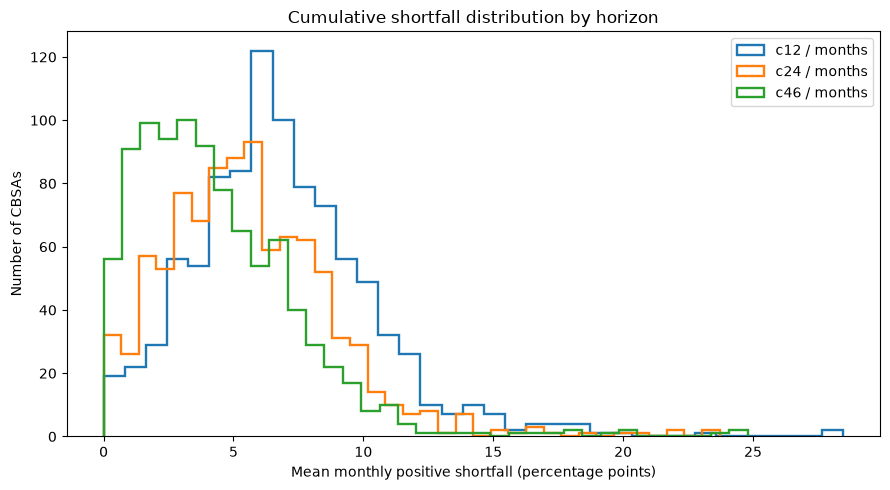

In [11]:
TARGETS={
    'c12':'cumulative_shortfall_12_pp_months',
    'c24':'cumulative_shortfall_24_pp_months',
    'c46':'cumulative_shortfall_46_pp_months',
}
SIGNED_SOURCE=PROC/'stage2_omb2018_monthly_gaps.csv'
if INCLUDE_SIGNED_46 and SIGNED_SOURCE.exists():
    monthly=pd.read_csv(SIGNED_SOURCE,dtype={'cbsa_code':'string'},parse_dates=['date'])
    monthly.cbsa_code=monthly.cbsa_code.str.zfill(5)
    assert monthly.groupby('cbsa_code').size().eq(46).all(), 'Incomplete monthly gaps'
    if 'gap_pct' not in monthly:
        monthly['gap_pct']=100*(monthly.employment/monthly.counterfactual_employment-1)
    if not monthly.gap_pct.notna().all(): raise ValueError('Missing monthly gaps')
    # Signed deficit can be negative if surpluses outweigh deficits.
    signed=-monthly.groupby('cbsa_code').gap_pct.sum().rename('signed_cumulative_gap_46_pp_months')
    df=df.merge(signed,on='cbsa_code',how='left',validate='one_to_one')
    TARGETS['signed46']='signed_cumulative_gap_46_pp_months'
    # Ensure that 46-month positive shortfall agrees with the earlier stage.
    check=monthly.assign(positive_shortfall=(-monthly.gap_pct).clip(lower=0))                 .groupby('cbsa_code').positive_shortfall.sum()
    reference=outcomes.set_index('cbsa_code')['cumulative_shortfall_46_pp_months']
    assert np.allclose(check.loc[reference.index],reference,rtol=1e-5,atol=1e-5), \
        'Stage 03 positive cumulative outcome differs from cached monthly series'
elif INCLUDE_SIGNED_46:
    print('Signed gap sensitivity skipped: stage2_omb2018_monthly_gaps.csv unavailable.')

for key,col in TARGETS.items():
    df[col]=pd.to_numeric(df[col],errors='coerce')
    if df[col].isna().any():raise ValueError(f'Missing target {col}')
    if key!='signed46' and (df[col]<0).any():raise ValueError('Positive cumulative deficit cannot be negative')
for a,b in [('c12','c24'),('c24','c46')]:
    if (df[TARGETS[a]]>df[TARGETS[b]]+1e-6).any():
        raise ValueError('Positive cumulative shortfall must be nondecreasing with horizon')

rows=[]
for key,col in TARGETS.items():
    s=df[col]
    rows.append({'target':key,'n':len(s),'mean':s.mean(),'median':s.median(),
                 'p90':s.quantile(.9),'p99':s.quantile(.99),'max':s.max(),
                 'skew':s.skew()})
describe=pd.DataFrame(rows)
describe.to_csv(OUT/(PREFIX+'target_distributions.csv'),index=False)
display(describe.round(2))
fig,ax=plt.subplots(figsize=(9,5))
for k in ('c12','c24','c46'):
    ax.hist(df[TARGETS[k]]/int(k[-2:]),bins=35,histtype='step',linewidth=1.7,
            label=k+' / months')
ax.set(xlabel='Mean monthly positive shortfall (percentage points)',ylabel='Number of CBSAs',
       title='Cumulative shortfall distribution by horizon')
ax.legend();fig.tight_layout()
fig.savefig(OUT/(PREFIX+'horizon_distributions.png'),dpi=170)
plt.show()

## 3. Fold-safe preprocessing and candidate models

- **Median benchmark:** fixed training-sample median, chosen as the MAE-oriented no-feature baseline; we also report the training mean.
- **Ridge:** standardize predictors, tune the penalty only within training divisions.
- **Log-Ridge:** fit `log1p(cumulative shortfall)` and transform predictions back to the original units; evaluate MAE on the original scale to prevent artificial gains from changing units. Not used for signed (potentially negative) gaps.
- **Nonlinear model:** small, predeclared histogram-gradient-boosting grid with absolute-error loss to capture nonlinearities and reduce sensitivity to extreme outcomes.

**Important:** The 50% variable coverage threshold is re-learned *inside each fitted fold*, not on the full sample. Industry suppression is never replaced with zero.

In [12]:
class CoverageSelector(BaseEstimator,TransformerMixin):
    def __init__(self,min_coverage=.50): self.min_coverage=min_coverage
    def fit(self,X,y=None):
        if not isinstance(X,pd.DataFrame):raise TypeError('Expected DataFrame with feature names')
        available=X.notna().mean()
        self.cols_=available.index[available>=self.min_coverage].tolist()
        if not self.cols_:
            raise ValueError('No features meet the training-fold coverage threshold')
        return self
    def transform(self,X):
        return X.loc[:,self.cols_].astype(float)

def plus0_inverse(z):
    return np.maximum(0,np.expm1(z))

def score_positive_mae(estimator,X,y):
    return -float(mean_absolute_error(y,np.maximum(0,np.asarray(estimator.predict(X)).ravel())))

def score_signed_mae(estimator,X,y):
    return -float(mean_absolute_error(y,np.asarray(estimator.predict(X)).ravel()))

def ridge_pipeline():
    return Pipeline([
        ('coverage',CoverageSelector(MIN_FEATURE_COVERAGE)),
        ('impute',SimpleImputer(strategy='median',add_indicator=True,keep_empty_features=True)),
        ('scale',StandardScaler()),
        ('model',Ridge())])

def hgb_pipeline():
    # HistGradientBoosting handles NaNs natively; do not need median imputation.
    return Pipeline([
        ('coverage',CoverageSelector(MIN_FEATURE_COVERAGE)),
        ('model',HistGradientBoostingRegressor(
            loss='absolute_error',learning_rate=.05,max_iter=160,
            min_samples_leaf=20,early_stopping=False,random_state=SEED))])

def candidates(target_key):
    items=[]
    for features in ('core','industry','combined'):
        items.append((f'ridge_{features}',features,ridge_pipeline(),
                      {'model__alpha':[1.0,100.0,1000.0]}))
    if target_key!='signed46':
        items.append(('log_ridge_combined','combined',TransformedTargetRegressor(
            regressor=ridge_pipeline(),func=np.log1p,
            inverse_func=plus0_inverse,check_inverse=False),
            {'regressor__model__alpha':[1.0,100.0,1000.0]}))
    if ENABLE_HGB:
        items.append(('hgb_combined','combined',hgb_pipeline(),
                      {'model__max_leaf_nodes':[7,15],
                       'model__l2_regularization':[1.0,10.0]}))
    return items

print('Candidate families:',[n for n,*_ in candidates('cum46')])

Candidate families: ['ridge_core', 'ridge_industry', 'ridge_combined', 'log_ridge_combined', 'hgb_combined']


## 4. Nested leave-one-division-out evaluation

The **outer division** is never used to choose the model or the hyperparameters. For each outer split, an inner 4-fold GroupKFold among *training divisions* chooses among the benchmark, feature sets, model families, and their hyperparameters using mean absolute error. The preselected winner makes one prediction for each untouched outer CBSA.

`MAX_OUTER_DIVISIONS=2` is intended **only for testing execution**, not for research conclusions. Set it to `0` for the full result. `ENABLE_HGB=False` can speed up initial benchmarking but changes the candidate set; report the setting used.

In [13]:
from sklearn.base import clone

def metrics(y,p):
    y=np.asarray(y,dtype=float).ravel()
    p=np.asarray(p,dtype=float).ravel()
    return {'mae':float(mean_absolute_error(y,p)),
            'rmse':float(np.sqrt(mean_squared_error(y,p))),
            'r2':float(r2_score(y,p)) if len(y)>1 else np.nan,
            'bias_pred_minus_actual':float(np.mean(p-y))}

outer=LeaveOneGroupOut()
folds=list(outer.split(df,groups=df.geographic_group))
if MAX_OUTER_DIVISIONS:
    folds=folds[:MAX_OUTER_DIVISIONS]
partial_run=MAX_OUTER_DIVISIONS>0
prediction_rows,fold_rows,decision_rows=[],[],[]
start=time.perf_counter()
for fold_no,(tr_idx,te_idx) in enumerate(folds,1):
    tr=df.iloc[tr_idx].copy()
    te=df.iloc[te_idx].copy()
    held_div=str(te.geographic_group.iloc[0])
    if te.geographic_group.nunique()!=1:
        raise RuntimeError('A test fold mixes Census divisions')
    if held_div in set(tr.geographic_group):
        raise RuntimeError('Geographic leakage')
    inner=GroupKFold(n_splits=min(4,tr.geographic_group.nunique()))
    print(f'Outer fold {fold_no}/{len(folds)}: {held_div}, train={len(tr)}, test={len(te)}',flush=True)
    for target_key,target_col in TARGETS.items():
        ytr=tr[target_col].to_numpy(dtype=float)
        yte=te[target_col].to_numpy(dtype=float)
        signed=target_key=='signed46'
        scorer=score_signed_mae if signed else score_positive_mae
        x_dummy=pd.DataFrame({'constant':np.ones(len(tr))},index=tr.index)
        with threadpool_limits(limits=1):
            median_cv=-float(cross_val_score(
                DummyRegressor(strategy='median'),x_dummy,ytr,groups=tr.geographic_group,
                cv=inner,scoring=scorer,n_jobs=1).mean())
        winner={'name':'training_median','features':'none','inner_cv_mae':median_cv,
                'params':{},'search':None}
        decision_rows.append({'outer_division':held_div,'target':target_key,
                              'candidate':'training_median','feature_set':'none',
                              'inner_cv_mae':median_cv,'best_params':'{}'})
        for name,feature_set,estimator,param_grid in candidates(target_key):
            gs=GridSearchCV(estimator,param_grid,cv=inner,scoring=scorer,
                            n_jobs=N_JOBS,refit=True,error_score='raise')
            with warnings.catch_warnings(),threadpool_limits(limits=1):
                warnings.filterwarnings('ignore',category=UserWarning)
                gs.fit(tr[FEATURE_SETS[feature_set]],ytr,groups=tr.geographic_group)
            cv_mae=-float(gs.best_score_)
            decision_rows.append({'outer_division':held_div,'target':target_key,
                                  'candidate':name,'feature_set':feature_set,
                                  'inner_cv_mae':cv_mae,'best_params':json.dumps(gs.best_params_)})
            if cv_mae < winner['inner_cv_mae']-1e-10:
                winner={'name':name,'features':feature_set,'inner_cv_mae':cv_mae,
                        'params':gs.best_params_,'search':gs}
        mean_pred=np.full(len(te),float(ytr.mean()))
        med_pred=np.full(len(te),float(np.median(ytr)))
        if winner['search'] is None:
            pred_hat=med_pred.copy()
        else:
            pred_hat=np.asarray(winner['search'].predict(
                te[FEATURE_SETS[winner['features']]]),dtype=float).ravel()
        if not signed:pred_hat=np.maximum(0,pred_hat)
        model_metrics=metrics(yte,pred_hat)
        mean_metrics=metrics(yte,mean_pred)
        med_metrics=metrics(yte,med_pred)
        fold_rows.append({
            'outer_division':held_div,'target':target_key,'n_test':len(te),
            'winner':winner['name'],'feature_set':winner['features'],
            'winner_inner_cv_mae':winner['inner_cv_mae'],
            'winner_best_params':json.dumps(winner['params']),
            **model_metrics,'mean_baseline_mae':mean_metrics['mae'],
            'median_baseline_mae':med_metrics['mae'],
            'skill_vs_mean_pct':100*(1-model_metrics['mae']/mean_metrics['mae']) if mean_metrics['mae']>0 else np.nan,
            'skill_vs_median_pct':100*(1-model_metrics['mae']/med_metrics['mae']) if med_metrics['mae']>0 else np.nan})
        for cbsa,actual,estimate,bmean,bmedian in zip(
                te.cbsa_code,yte,pred_hat,mean_pred,med_pred):
            prediction_rows.append({
                'cbsa_code':str(cbsa),'outer_division':held_div,
                'target':target_key,'observed':float(actual),'predicted':float(estimate),
                'baseline_mean':float(bmean),'baseline_median':float(bmedian),
                'winner':winner['name'],'feature_set':winner['features']})
    print('  Completed:',held_div,'elapsed minutes:',round((time.perf_counter()-start)/60,1),flush=True)
    # Checkpoints ensure partial progress survives a notebook interruption.
    pd.DataFrame(prediction_rows).to_csv(OUT/(PREFIX+'nested_predictions_PARTIAL.csv'),index=False)
    pd.DataFrame(fold_rows).to_csv(OUT/(PREFIX+'outer_fold_scores_PARTIAL.csv'),index=False)

predictions=pd.DataFrame(prediction_rows)
fold_scores=pd.DataFrame(fold_rows)
decisions=pd.DataFrame(decision_rows)
if not partial_run:
    for key in TARGETS:
        ids=set(predictions.loc[predictions.target.eq(key),'cbsa_code'])
        if len(ids)!=len(df) or ids!=set(df.cbsa_code):
            raise ValueError('Full leave-one-division-out predictions do not cover all CBSAs')
for frame,filename in (
    (predictions,'nested_predictions.csv'),
    (fold_scores,'outer_fold_scores.csv'),
    (decisions,'inner_cv_decisions.csv')):
    suffix='_PARTIAL' if partial_run else ''
    frame.to_csv(OUT/(PREFIX+filename.replace('.csv',suffix+'.csv')),index=False)
print('Nested CV finished; total minutes:',round((time.perf_counter()-start)/60,1))
display(fold_scores.head())

Outer fold 1/10: East North Central, train=775, test=161
  Completed: East North Central elapsed minutes: 0.1
Outer fold 2/10: East South Central, train=841, test=95
  Completed: East South Central elapsed minutes: 0.1
Outer fold 3/10: Middle Atlantic, train=870, test=66
  Completed: Middle Atlantic elapsed minutes: 0.2
Outer fold 4/10: Mountain, train=843, test=93
  Completed: Mountain elapsed minutes: 0.2
Outer fold 5/10: New England, train=910, test=26
  Completed: New England elapsed minutes: 0.3
Outer fold 6/10: Pacific, train=854, test=82
  Completed: Pacific elapsed minutes: 0.4
Outer fold 7/10: Puerto Rico, train=924, test=12
  Completed: Puerto Rico elapsed minutes: 0.4
Outer fold 8/10: South Atlantic, train=785, test=151
  Completed: South Atlantic elapsed minutes: 0.5
Outer fold 9/10: West North Central, train=816, test=120
  Completed: West North Central elapsed minutes: 0.5
Outer fold 10/10: West South Central, train=806, test=130
  Completed: West South Central elapsed mi

,outer_division,target,n_test,winner,feature_set,winner_inner_cv_mae,winner_best_params,mae,rmse,r2,bias_pred_minus_actual,mean_baseline_mae,median_baseline_mae,skill_vs_mean_pct,skill_vs_median_pct
0,East North Central,c12,161,hgb_combined,combined,29.597358,"{""model__l2_regularization"": 10.0, ""model__max...",24.216578,31.952608,-0.178591,-8.699612,23.589786,24.911953,-2.657050,2.791331
1,East North Central,c24,161,hgb_combined,combined,56.978761,"{""model__l2_regularization"": 1.0, ""model__max_...",47.642888,61.674745,-0.140355,-13.254255,46.628529,49.651069,-2.175404,4.044586
2,East North Central,c46,161,hgb_combined,combined,105.493196,"{""model__l2_regularization"": 10.0, ""model__max...",91.949684,117.146499,-0.056643,-33.807859,93.695885,100.144537,1.863690,8.183026
3,East North Central,signed46,161,ridge_combined,combined,143.751395,"{""model__alpha"": 1000.0}",108.881870,134.585630,0.044814,-32.584310,118.503147,118.389912,8.119005,8.031125
4,East South Central,c12,95,ridge_combined,combined,29.759158,"{""model__alpha"": 100.0}",23.142516,29.701706,-0.154098,3.036214,26.240752,24.369691,11.806964,5.035663


## 5. Report pooled accuracy, division-level heterogeneity, and uncertainty

The pooled row combines one strictly out-of-division prediction per CBSA. Report both MAE (and improvement over training-only benchmarks) and R². For comparability across horizons, MAE divided by 12/24/46 is expressed as an error in the average monthly shortfall (percentage points), not a new model fit. The interval resamples *divisions* rather than CBSAs, but with only about nine divisions it should be treated as an exploratory stability diagnostic.

In [14]:
pooled_rows=[]
for key, s in predictions.groupby('target',sort=False):
    y=s.observed.to_numpy(float)
    p=s.predicted.to_numpy(float)
    bmean=s.baseline_mean.to_numpy(float)
    bmed=s.baseline_median.to_numpy(float)
    chosen=metrics(y,p)
    mae_mean=mean_absolute_error(y,bmean)
    mae_med=mean_absolute_error(y,bmed)
    horizon={'c12':12,'c24':24,'c46':46,'signed46':46}[key]
    pooled_rows.append({'target':key,'n_cbsa':len(s),'n_divisions':s.outer_division.nunique(),
                        'mae':chosen['mae'],'mae_per_month':chosen['mae']/horizon,
                        'rmse':chosen['rmse'],'r2':chosen['r2'],
                        'bias_pred_minus_actual':chosen['bias_pred_minus_actual'],
                        'baseline_mean_mae':mae_mean,'baseline_median_mae':mae_med,
                        'skill_vs_mean_pct':100*(1-chosen['mae']/mae_mean) if mae_mean>0 else np.nan,
                        'skill_vs_median_pct':100*(1-chosen['mae']/mae_med) if mae_med>0 else np.nan,
                        'median_division_skill_pct':float(fold_scores.loc[fold_scores.target.eq(key),'skill_vs_median_pct'].median())})
pooled=pd.DataFrame(pooled_rows)
suffix='_PARTIAL' if partial_run else ''
pooled.to_csv(OUT/(PREFIX+'pooled_scores'+suffix+'.csv'),index=False)
selection=(fold_scores.groupby(['target','winner','feature_set'],as_index=False)
           .agg(outer_divisions_selected=('outer_division','size')))
selection.to_csv(OUT/(PREFIX+'selection_counts'+suffix+'.csv'),index=False)
print('Pooled performance (partial smoke test)' if partial_run else 'Pooled nested geographic CV performance')
display(pooled.round(3))
display(selection.sort_values(['target','outer_divisions_selected'],ascending=[True,False]))

# Cluster bootstrap of paired improvement, using a region-weighted MAE. 
# It is descriptive due to the small number of Census divisions.
rng=np.random.default_rng(SEED)
boot_rows=[]
for key,s in predictions.groupby('target'):
    d=list(s.outer_division.unique())
    grouped={g:s.loc[s.outer_division.eq(g)] for g in d}
    if len(d)<4:continue
    diffs=[]
    for _ in range(BOOTSTRAP_REPS):
        sampled=rng.choice(d,size=len(d),replace=True)
        errors=np.concatenate([np.abs(grouped[g].observed.values-grouped[g].predicted.values) for g in sampled])
        baselines=np.concatenate([np.abs(grouped[g].observed.values-grouped[g].baseline_median.values) for g in sampled])
        diffs.append(np.mean(baselines)-np.mean(errors))
    boot_rows.append({'target':key,'mae_advantage_over_median_pp_months':float(np.mean(diffs)),
                      'bootstrap_p2_5':float(np.quantile(diffs,.025)),
                      'bootstrap_p97_5':float(np.quantile(diffs,.975)),
                      'n_divisions':len(d)})
boot=pd.DataFrame(boot_rows,columns=['target','mae_advantage_over_median_pp_months',
                                    'bootstrap_p2_5','bootstrap_p97_5','n_divisions'])
boot.to_csv(OUT/(PREFIX+'division_bootstrap'+suffix+'.csv'),index=False)
if not boot.empty:display(boot.round(3))

Pooled nested geographic CV performance


,target,n_cbsa,n_divisions,mae,mae_per_month,rmse,r2,bias_pred_minus_actual,baseline_mean_mae,baseline_median_mae,skill_vs_mean_pct,skill_vs_median_pct,median_division_skill_pct
0,c12,936,10,29.012,2.418,39.278,0.113,-0.496,31.713,31.433,8.518,7.703,4.668
1,c24,936,10,57.337,2.389,76.273,0.043,-2.425,59.464,59.328,3.577,3.357,3.474
2,c46,936,10,105.678,2.297,145.153,0.004,-15.254,109.563,108.299,3.546,2.420,2.169
3,signed46,936,10,139.104,3.024,197.197,0.001,2.755,142.269,142.949,2.225,2.690,2.899


,target,winner,feature_set,outer_divisions_selected
1,c12,ridge_combined,combined,6
0,c12,hgb_combined,combined,4
2,c24,hgb_combined,combined,5
3,c24,ridge_combined,combined,5
4,c46,hgb_combined,combined,6
6,c46,ridge_combined,combined,3
5,c46,log_ridge_combined,combined,1
8,signed46,ridge_combined,combined,6
7,signed46,hgb_combined,combined,4


,target,mae_advantage_over_median_pp_months,bootstrap_p2_5,bootstrap_p97_5,n_divisions
0,c12,2.545,1.121,4.700,10
1,c24,2.044,0.523,4.207,10
2,c46,2.745,-2.018,8.226,10
3,signed46,4.021,-1.019,9.431,10


## 6. Visual diagnostics and largest residuals

Large 46-month errors may reflect inherently difficult extrapolation rather than poor fitting of the cross-sectional model alone. Inspect and report the outlying areas; do not delete them just to improve results.

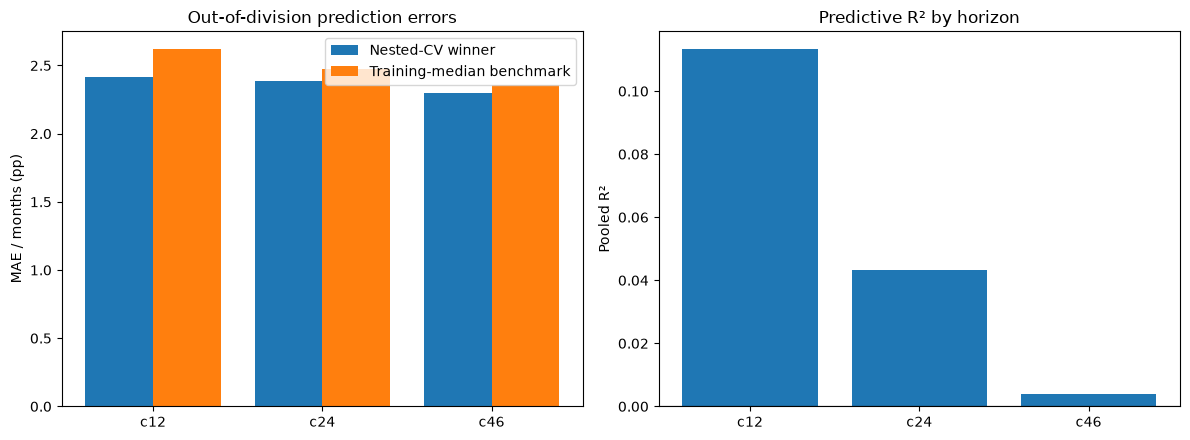

Largest out-of-division residuals (do not remove automatically)


,cbsa_code,outer_division,target,observed,predicted,baseline_mean,baseline_median,winner,feature_set,residual_pred_minus_actual,abs_error
3581,37770,West South Central,c46,1084.869690,280.621937,199.796005,179.141265,ridge_combined,combined,-804.247753,804.247753
1485,16100,Mountain,c46,1140.699431,343.189720,202.150274,178.984055,ridge_combined,combined,-797.509710,797.509710
3504,14300,West South Central,c46,1136.698470,356.892377,199.796005,179.141265,ridge_combined,combined,-779.806093,779.806093
3549,29340,West South Central,c46,762.769228,0.000000,199.796005,179.141265,ridge_combined,combined,-762.769228,762.769228
2579,46420,South Atlantic,c46,935.017011,177.485009,201.549707,175.247117,hgb_combined,combined,-757.532001,757.532001
3613,49820,West South Central,c46,822.287305,132.774016,199.796005,179.141265,ridge_combined,combined,-689.513289,689.513289
1956,28180,Pacific,c46,919.533751,242.530833,194.721954,168.476243,hgb_combined,combined,-677.002918,677.002918
2570,44900,South Atlantic,c46,791.606689,127.747551,201.549707,175.247117,hgb_combined,combined,-663.859138,663.859138
1210,42900,Middle Atlantic,c46,719.320761,130.899099,191.985045,163.719144,hgb_combined,combined,-588.421662,588.421662
3098,48780,West North Central,c46,896.515353,339.612046,203.528769,179.732779,ridge_combined,combined,-556.903307,556.903307


In [17]:
fig,axs=plt.subplots(1,2,figsize=(12,4.5))
seq=[k for k in ('c12','c24','c46') if k in set(pooled.target)]
bar=pooled.set_index('target').loc[seq]
xs=np.arange(len(seq))
axs[0].bar(xs-.20,bar.mae_per_month.to_numpy()/1, width=.4,label='Nested-CV winner')
axs[0].bar(xs+.20,np.array([bar.loc[k,'baseline_median_mae']/int(k[-2:]) for k in seq]),
           width=.4,label='Training-median benchmark')
axs[0].set(xticks=xs,xticklabels=seq,ylabel='MAE / months (pp)',
           title='Out-of-division prediction errors')
axs[0].legend()
axs[1].bar(seq,bar.r2.values)
axs[1].axhline(0,color='black',linewidth=.8)
axs[1].set(ylabel='Pooled R²',title='Predictive R² by horizon')
fig.tight_layout();fig.savefig(OUT/(PREFIX+'geographic_comparison.png'),dpi=170)
plt.show()

resids=predictions.copy()
resids['residual_pred_minus_actual']=resids.predicted-resids.observed
resids['abs_error']=resids.residual_pred_minus_actual.abs()
worst=(resids.sort_values('abs_error',ascending=False)
       .groupby('target',group_keys=False).head(20))
worst.to_csv(OUT/(PREFIX+'largest_residuals'+suffix+'.csv'),index=False)
print('Largest out-of-division residuals (do not remove automatically)')
display(worst.loc[worst.target.eq('c46')].head(10))

## 7. Audit manifest and interpretation checklist

**A stronger result** means genuine improvement against the training-only median benchmark across multiple held-out divisions, with a positive pooled R² and an uncertainty interval that does not suggest severe instability. If this fails for 46 months, report the weak predictability rather than replacing the original outcome. If 12 or 24 months performs better, present that as evidence that the pre-pandemic structural predictors are more informative for *nearer-term* cumulative deficits.

Possible substantive reasons for weak 46-month predictability: policy and health developments after 2020, regional demand shifts, migration, structural breaks, and large forecast uncertainty at horizons exceeding four years. These explanations are **hypotheses** and cannot be established from forecast residuals alone.

The original shortfall metric truncates surpluses at zero. If the signed 46-month metric was available, compare its model skill and regional rankings as a sensitivity analysis; do not silently replace the original positive-deficit area.

In [18]:
manifest={
 'created_utc':datetime.now(timezone.utc).isoformat(),
 'pipeline_step':'05 cumulative shortfall geographic validation',
 'geographic_vintage':'2018-09','stage2_information_cutoff':'2020-02-29',
 'stage1_training_cutoff':'2019-06-01',
 'predictor_sha256':sha256(p_path),'outcomes_sha256':sha256(o_path),
 'outcomes':TARGETS,'feature_sets':FEATURE_SETS,
 'n_geographic_divisions':int(df.geographic_group.nunique()),
 'n_outer_divisions_evaluated':int(len(folds)),
 'partial_smoke_test':bool(partial_run),
 'model_candidates':[name for name,*_ in candidates('cum46')],
 'n_jobs':N_JOBS,'enable_hgb':ENABLE_HGB,'min_feature_coverage':MIN_FEATURE_COVERAGE,
 'inner_cv':'GroupKFold(4) nested within leave-one-Census-division-out',
 'selection_metric':'MAE on original target scale',
 'reported_metrics':'MAE, RMSE, R², mean prediction bias, skill vs training mean and median',
 'sklearn':sklearn.__version__,'python':platform.python_version(),
 'limitations':['2018 delineations do not guarantee historical QCEW as-of publication vintages',
                'Forecast 2019-07 to 2023-12 is a long extrapolation after 2019-Q2',
                'Industry missingness is not random; imputation applies only within training folds',
                'Only about 9 geographic divisions; group-bootstrap intervals are exploratory',
                'Outcome associations are predictive and not causal']
}
(OUT/(PREFIX+'manifest'+('_PARTIAL' if partial_run else '')+'.json')).write_text(
    json.dumps(manifest,indent=2))
print('Finished. Output prefix:',OUT/PREFIX)
print('Do not cite PARTIAL smoke-test results as complete national geographic validation.')

Finished. Output prefix: c:\Users\adamt\OneDrive\Documents\Directed Practicum\regional-labor-resilience\output\stage2_cumulative05_
Do not cite PARTIAL smoke-test results as complete national geographic validation.
